In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF
from functions import AlgCoM
from functions import AlgYe
from functions import AlgProxPen

In [2]:
#X,Y must be a box
Y=[(0,1)]
n=3
X=[]
def fcp(x):
    return x[-1]

def fs(x):
    return np.sin(np.pi*x)
    
def gcp(x,y):
    return cp.abs(cp.sum([x[i]*y**i for i in range(n)])-fs(y))-x[-1]

def f(x):
    return x[-1]

def df(x):
    v=np.zeros(n+1)
    v[-1]=1
    return v


def g(x,y):
    return np.abs(np.sum([x[i]*y**i for i in range(n)])-fs(y))-x[-1]

def dg(x,y):
    v=np.zeros(n+1)
    v[-1]=-1
    for i in range(n):
        if np.sum([x[i]*y**i for i in range(n)])-fs(y)>0:
            v[i]=y**i
        else:
            v[i]=-y**i
    return v

def poly(d,coeff,x):
    return np.sum([coeff[i]*x**i for i in range(d)])

In [3]:
y0=np.array([[0.5]])
x0=np.zeros(n+1)
res1=AlgProxPen(x0,y0,fcp,gcp,g,X,Y,f=fcp,df=df,rho=1)

[[0.5]]
[[0.5       ]
 [0.49923792]]
[[0.5       ]
 [0.49923792]
 [0.49771376]]
[[0.5       ]
 [0.49923792]
 [0.49771376]
 [0.49471625]]
[[0.5       ]
 [0.49923792]
 [0.49771376]
 [0.49471625]
 [0.48877204]]
[[0.5       ]
 [0.49923792]
 [0.49771376]
 [0.49471625]
 [0.48877204]
 [0.47722231]]
0.0
Time 0.22087645530700684
Time upper problem 0.10887789726257324
Time lower problem 0.10882830619812012
Feasibility 8.079191637000438e-05
Final rho 32
Rho increases 5
Optimal value 0.5400358449217637
Value function call 7


In [5]:
res2=AlgYe(x0,y0,fcp,gcp,fcp,g,df,dg,X,Y)

KeyboardInterrupt: 

In [4]:
res3=AlgMePa(x0,y0,fcp,gcp,g,X,Y)
print(res3[0])

[0.99999969]
[3.13612737e-07]
[0.84976037]
[0.11802909]
[0.14850661]
Time 0.25630784034729004
Time upper problem 0.14650511741638184
Time lower problem 0.1098027229309082
Feasibility -7.852033922482043e-06
Optimal value 0.028008386971323747
Optimality cuts 3
Feasibility cuts 6
Value function calls 9
[-0.02800844  4.00001349 -4.00001113  0.02800553]


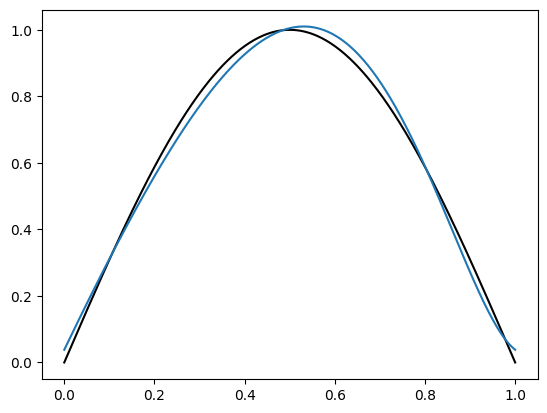

In [12]:
N = 400
x = np.linspace(Y[0][0], Y[0][1], N)


fig, ax = plt.subplots()
ax.plot(x, fs(x), "k")
poly1=[poly(n,res1[0],xi) for xi in x]
ax.plot(x, poly1)

In [38]:
v=np.zeros(2)

np.float64(0.0)